# Q2 - Data quality and outliers

How reliable is the data, and which anomalies or outliers should we handle before modelling?

Plan: missing values, duplicates and consistency, violin plots (global and per category), kills/death scatterplot, next steps.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from matplotlib.colors import LogNorm

sns.set_theme(style='whitegrid')

DATA_PATH: Path = Path('playersmatches_test - playersmatches_test.csv')
NUM_COLUMNS: list[str] = ['kills', 'death', 'playernb_in_match']

df_player_matches: pl.DataFrame = pl.read_csv(
    DATA_PATH,
    infer_schema=False,
    null_values=['null'],
).with_columns(
    pl.col('match_datetime').str.to_datetime(time_zone='UTC', strict=False),
    pl.col(*NUM_COLUMNS).cast(pl.Int64, strict=False),
    (pl.col('still_active') == 'TRUE').alias('still_active'),
)
row_count: int = df_player_matches.height
print(df_player_matches.shape)

FileNotFoundError: Le fichier spécifié est introuvable. (os error 2): playersmatches_test - playersmatches_test.csv

## 1. Missing values

shape: (11, 3)
┌───────────────────┬────────────┬──────────┐
│ column            ┆ null_count ┆ null_pct │
│ ---               ┆ ---        ┆ ---      │
│ str               ┆ u32        ┆ f64      │
╞═══════════════════╪════════════╪══════════╡
│ kills             ┆ 153        ┆ 0.16     │
│ death             ┆ 153        ┆ 0.16     │
│ opponentid        ┆ 11         ┆ 0.011    │
│ teammateid        ┆ 6          ┆ 0.006    │
│ playerid          ┆ 0          ┆ 0.0      │
│ …                 ┆ …          ┆ …        │
│ gamemode          ┆ 0          ┆ 0.0      │
│ victory           ┆ 0          ┆ 0.0      │
│ match_datetime    ┆ 0          ┆ 0.0      │
│ playernb_in_match ┆ 0          ┆ 0.0      │
│ still_active      ┆ 0          ┆ 0.0      │
└───────────────────┴────────────┴──────────┘


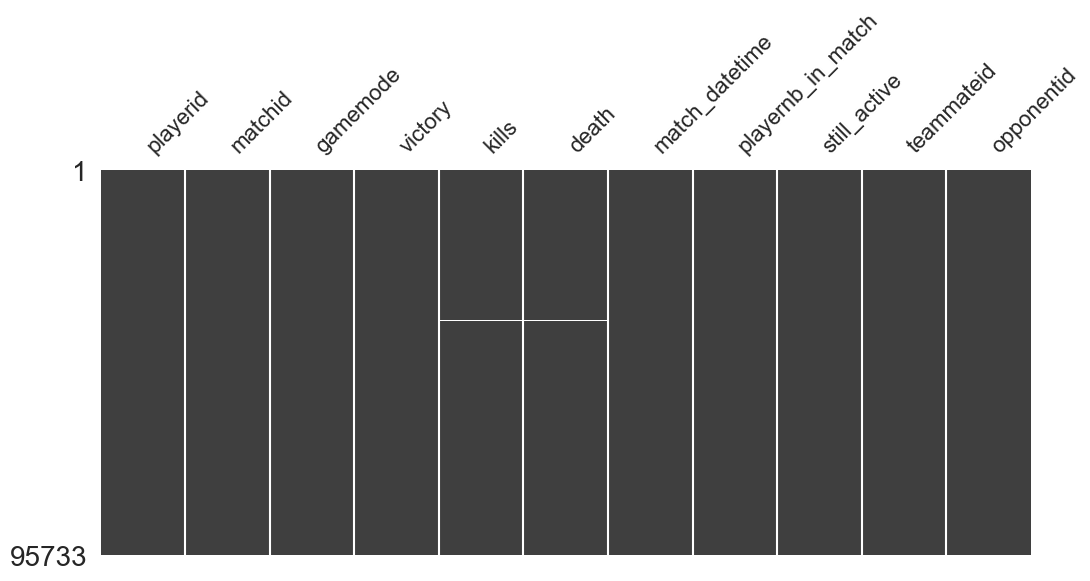

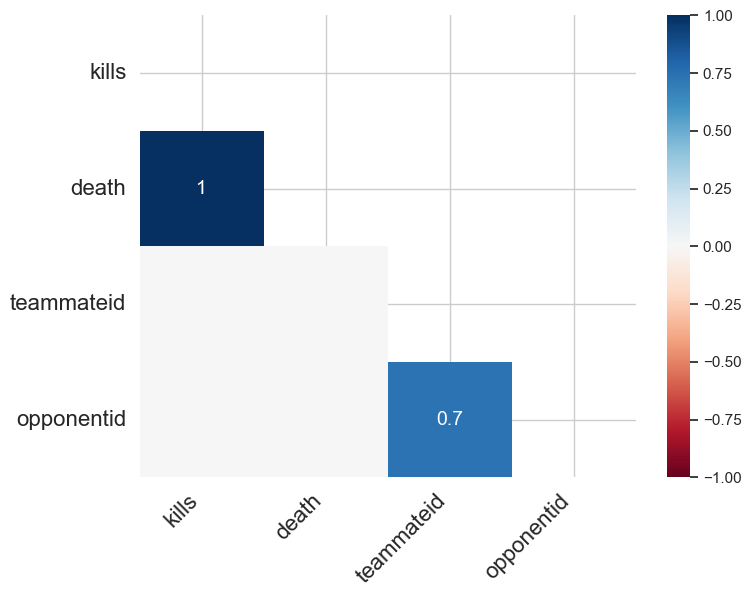

In [ ]:
null_summary: pl.DataFrame = (
    df_player_matches.null_count()
    .transpose(include_header=True, header_name='column', column_names=['null_count'])
    .with_columns((pl.col('null_count') / row_count * 100).round(3).alias('null_pct'))
    .sort('null_count', descending=True)
)
print(null_summary)

# missingno works on pandas
msno.matrix(df_player_matches.to_pandas(), figsize=(12, 5), sparkline=False)
plt.show()
msno.heatmap(df_player_matches.to_pandas(), figsize=(8, 6))
plt.show()

Observation:
- Only 3 groups of columns have nulls: `kills`/`death` (153 rows, **always null together**), `teammateid` (6), `opponentid` (11).
- Overall completeness is above 99.8%, nulls are not a blocker.
- Check whether the null kills/death are random or tied to a mode / result / date.

In [ ]:
df_null_performance: pl.DataFrame = df_player_matches.filter(pl.col('kills').is_null())
print(df_null_performance.group_by('gamemode', 'victory').len().sort('gamemode', 'victory'))
print(df_null_performance['match_datetime'].dt.date().value_counts().sort('match_datetime'))
print('distinct players concerned:', df_null_performance['playerid'].n_unique())

shape: (6, 3)
┌──────────────┬─────────┬─────┐
│ gamemode     ┆ victory ┆ len │
│ ---          ┆ ---     ┆ --- │
│ str          ┆ str     ┆ u32 │
╞══════════════╪═════════╪═════╡
│ PVP          ┆ FALSE   ┆ 24  │
│ PVP          ┆ TRUE    ┆ 22  │
│ PVP_RANKED   ┆ FALSE   ┆ 38  │
│ PVP_RANKED   ┆ TRUE    ┆ 42  │
│ PVP_UNRANKED ┆ FALSE   ┆ 13  │
│ PVP_UNRANKED ┆ TRUE    ┆ 14  │
└──────────────┴─────────┴─────┘
shape: (2, 2)
┌────────────────┬───────┐
│ match_datetime ┆ count │
│ ---            ┆ ---   │
│ date           ┆ u32   │
╞════════════════╪═══════╡
│ 2025-10-10     ┆ 1     │
│ 2025-12-09     ┆ 152   │
└────────────────┴───────┘
distinct players concerned: 43


## 2. Duplicates and consistency

In [ ]:
print('duplicated (player, match):', row_count - df_player_matches.select('playerid', 'matchid').unique().height)
print('matchid appearing more than once (rows):', row_count - df_player_matches['matchid'].n_unique())
print('fully duplicated rows:', row_count - df_player_matches.unique().height)

# a match with 2 rows should have 2 different players in the same lobby
df_player_matches.filter(pl.col('matchid').is_duplicated()).sort('matchid').select(
    'matchid', 'playerid', 'gamemode', 'victory', 'kills', 'death', 'playernb_in_match'
)

duplicated (player, match): 0
matchid appearing more than once (rows): 11
fully duplicated rows: 0


matchid,playerid,gamemode,victory,kills,death,playernb_in_match
str,str,str,str,i64,i64,i64
"""03080a9e-d0a0-4338-bff7-c63a5a…","""88cba154-adfc-4d84-8a69-186f73…","""PVP""","""FALSE""",4,3,10
"""03080a9e-d0a0-4338-bff7-c63a5a…","""4e5dc5a9-f7a0-41fd-8918-e2300f…","""PVP""","""TRUE""",3,3,10
"""1767c1fb-8d41-489f-b381-d17bb8…","""a4b3846c-4ad7-485e-9f44-6b48b9…","""PVP_RANKED""","""FALSE""",5,6,10
"""1767c1fb-8d41-489f-b381-d17bb8…","""6f8e17d9-98d0-4c9d-aaa2-8bdd60…","""PVP_RANKED""","""TRUE""",5,7,10
"""3339abe7-ea37-4386-ae67-bbec9e…","""04964954-a0f6-4749-aefc-f76c4d…","""PVP""","""FALSE""",0,0,13
…,…,…,…,…,…,…
"""fcf4793c-53c4-457a-bb88-fbdfc6…","""8586b23e-95da-4486-a91b-8f4000…","""PVP""","""FALSE""",4,4,14
"""fdb6d7b6-b8b9-46e9-9846-42732d…","""8dbab1dd-3c40-4b6f-a6f1-e62a88…","""PVP_RANKED""","""FALSE""",5,5,10
"""fdb6d7b6-b8b9-46e9-9846-42732d…","""6f8e17d9-98d0-4c9d-aaa2-8bdd60…","""PVP_RANKED""","""TRUE""",10,3,10


Observation on nulls:
- The null kills/death are spread across modes and results (no link with victory), but **152 of the 153 are on a single day, 2025-12-09**, across 43 players: this is a **logging / ingestion incident**, not random missingness. Do not impute, drop or flag them.

Observation on duplicates:
- `(player, match)` is a clean key, no duplicated rows.
- 11 `matchid` values come twice: two tracked players played the same match (we only have 840 players, not the full lobby).
- So **one row = one player in a match**, and `playernb_in_match` is the lobby size, not the number of rows we hold.

In [ ]:
# Logical consistency checks
print('zero kills AND zero deaths  :', df_player_matches.filter((pl.col('kills') == 0) & (pl.col('death') == 0)).height)
print('OPERATIONS rows             :', df_player_matches.filter(pl.col('gamemode') == 'OPERATIONS').height)
print('lobby size != 10            :', df_player_matches.filter(pl.col('playernb_in_match') != 10).height)
print('lobby size < 4 (solo)       :', df_player_matches.filter(pl.col('playernb_in_match') < 4).height)
print('draw / other                :', df_player_matches.filter(pl.col('victory').is_in(['draw', 'other'])).height)
print('max death                   :', df_player_matches['death'].max())
print(df_player_matches['death'].value_counts().sort('death'))

zero kills AND zero deaths  : 2134
OPERATIONS rows             : 5
lobby size != 10            : 25605
lobby size < 4 (solo)       : 6
draw / other                : 56
max death                   : 9
shape: (11, 2)
┌───────┬───────┐
│ death ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ null  ┆ 153   │
│ 0     ┆ 4082  │
│ 1     ┆ 9041  │
│ 2     ┆ 12678 │
│ 3     ┆ 19145 │
│ …     ┆ …     │
│ 5     ┆ 14544 │
│ 6     ┆ 7224  │
│ 7     ┆ 3732  │
│ 8     ┆ 1714  │
│ 9     ┆ 292   │
└───────┴───────┘


Observation:
- `death` stops at **9** with a sharp drop (few rows at 9, nothing at 10): looks like a cap tied to the round design. Needs confirming with the game team.
- 2,134 rows with 0 kills and 0 deaths (947 ranked, 1,144 PVP, 43 unranked): probably AFK / disconnect / left early, to be flagged.
- `playernb_in_match` is not always 10: 25.6k rows differ. Ranked / unranked are almost always 10 (5-7% differ, probably players who left); `PVP` is 68% different, up to 25.

## 3. Players per game: does `playernb_in_match` match the teammate / opponent lists?

`teammateid` and `opponentid` hold comma separated player ids. Number of ids = number of commas + 1 (0 if null).
Expected if the lobby size is right: `n_teammate + n_opponent + 1 (the player himself) = playernb_in_match`.
Also check whether `playerid` appears in its own `teammateid` (or `opponentid`).

In [ ]:
df_lobby: pl.DataFrame = df_player_matches.with_columns(
    pl.col('teammateid').fill_null('').str.count_matches(',').alias('comma_teammate'),
    pl.col('opponentid').fill_null('').str.count_matches(',').alias('comma_opponent'),
).with_columns(
    pl.when(pl.col('teammateid').is_null()).then(0).otherwise(pl.col('comma_teammate') + 1).cast(pl.Int64).alias('n_teammate'),
    pl.when(pl.col('opponentid').is_null()).then(0).otherwise(pl.col('comma_opponent') + 1).cast(pl.Int64).alias('n_opponent'),
    pl.col('teammateid').fill_null('').str.contains(pl.col('playerid'), literal=True).alias('self_in_teammate'),
    pl.col('opponentid').fill_null('').str.contains(pl.col('playerid'), literal=True).alias('self_in_opponent'),
).with_columns(
    (pl.col('n_teammate') + pl.col('n_opponent')).alias('n_listed'),
).with_columns(
    (pl.col('n_listed') - pl.col('playernb_in_match')).alias('gap_without_self'),
    (pl.col('n_listed') + 1 - pl.col('playernb_in_match')).alias('gap_with_self'),
    (pl.col('n_teammate') + 1 - pl.col('n_opponent')).alias('team_size_gap'),
)

print('playerid found in its own teammateid :', df_lobby['self_in_teammate'].sum(), 'rows')
print('playerid found in its own opponentid :', df_lobby['self_in_opponent'].sum(), 'rows')
print()
print('gap if player is NOT counted (n_listed - playernb_in_match):')
print(df_lobby['gap_without_self'].value_counts().sort('gap_without_self'))
print('gap if player IS counted (n_listed + 1 - playernb_in_match):')
print(df_lobby['gap_with_self'].value_counts().sort('gap_with_self'))

Observation:
- `playerid` is **never** in its own `teammateid` (nor `opponentid`): the teammate list contains the *other* players only.
- Once the player himself is added (+1), `n_teammate + n_opponent + 1 = playernb_in_match` holds on **100% of rows**: `playernb_in_match` is reliable, and lobbies that are not 10 are really smaller / bigger lobbies, not a counting error.
- Next: how balanced are the two teams (player's team = `n_teammate + 1` vs opponents)?

In [ ]:
df_team_balance: pl.DataFrame = (
    df_lobby.group_by('gamemode')
    .agg(
        pl.len().alias('rows'),
        (pl.col('team_size_gap') == 0).mean().round(3).alias('share_balanced'),
        (pl.col('n_teammate') + 1).mode().first().alias('team_size_mode'),
        pl.col('n_opponent').mode().first().alias('opponent_size_mode'),
        pl.col('team_size_gap').min().alias('gap_min'),
        pl.col('team_size_gap').max().alias('gap_max'),
    )
    .sort('rows', descending=True)
)
print(df_team_balance)

df_lobby.filter(pl.col('team_size_gap') != 0).group_by('gamemode', 'team_size_gap').len().sort('gamemode', 'team_size_gap')

Observation:
- Typical lobby is 5 vs 5 (team size mode = 5).
- Ranked (95%) and unranked (93%) are almost always 5 vs 5; the rest are mostly +/-1 (a player left or a late join).
- `PVP` is balanced in only **38%** of rows, with team size gaps from -11 to +14: not a fixed 5v5 format (custom / open lobbies), which confirms it should be analysed separately.
- `OPERATIONS`: 5 rows, 1 player and no opponent (PvE), team gap of +1 by construction.
- 6 rows with an empty `teammateid` and 11 with an empty `opponentid` are the nulls seen in section 1.

## 4. Violin plot of numerical columns

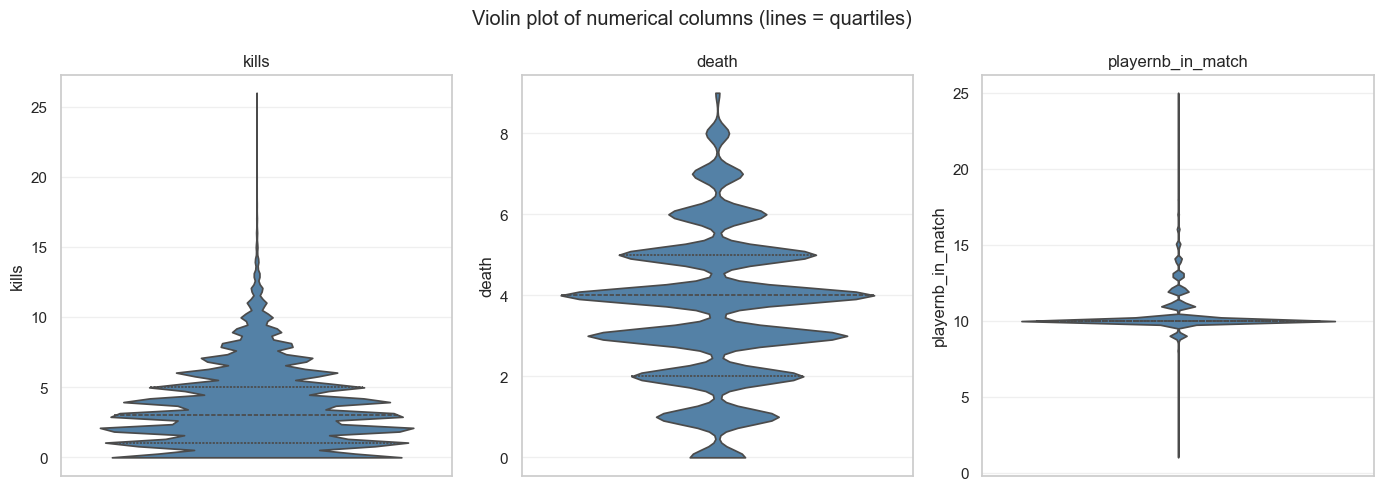

column,low,high,n_outliers,outlier_pct
str,f64,f64,i64,f64
"""kills""",-5.0,11.0,1106,1.16
"""death""",-2.5,9.5,0,0.0
"""playernb_in_match""",10.0,10.0,25605,26.75


In [ ]:
df_pandas = df_player_matches.to_pandas()

fig, axes = plt.subplots(1, len(NUM_COLUMNS), figsize=(14, 5))
for ax, column_name in zip(axes, NUM_COLUMNS):
    sns.violinplot(data=df_pandas, y=column_name, inner='quartile', cut=0, color='steelblue', ax=ax)
    ax.set_title(column_name)
    ax.grid(axis='y', alpha=0.3)
fig.suptitle('Violin plot of numerical columns (lines = quartiles)')
fig.tight_layout()
plt.show()


def iqr_outlier_count(column_name: str) -> dict:
    values = df_player_matches[column_name].drop_nulls()
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return {
        'column': column_name,
        'low': low,
        'high': high,
        'n_outliers': int(((values < low) | (values > high)).sum()),
    }


pl.DataFrame([iqr_outlier_count(c) for c in NUM_COLUMNS]).with_columns(
    (pl.col('n_outliers') / row_count * 100).round(2).alias('outlier_pct')
)

Observation:
- `kills` is right-skewed with a long tail up to 26 (above 12 = top 1%). The 160 rows with 15+ kills are 71% wins and all in 10-player ranked / unranked lobbies (except 1): **likely real top performers, not errors** (keep, maybe cap or log for models).
- `death` is bounded 0-9, almost no outlier.
- `playernb_in_match`: the distribution collapses on 10 and everything else is flagged as outlier. **This is not noise, it is a different type of match** (see below).

## 5. Violin plot of numerical columns per categorical column

Split violins: each game mode shows the two levels of `victory` (and of `still_active`) side by side.

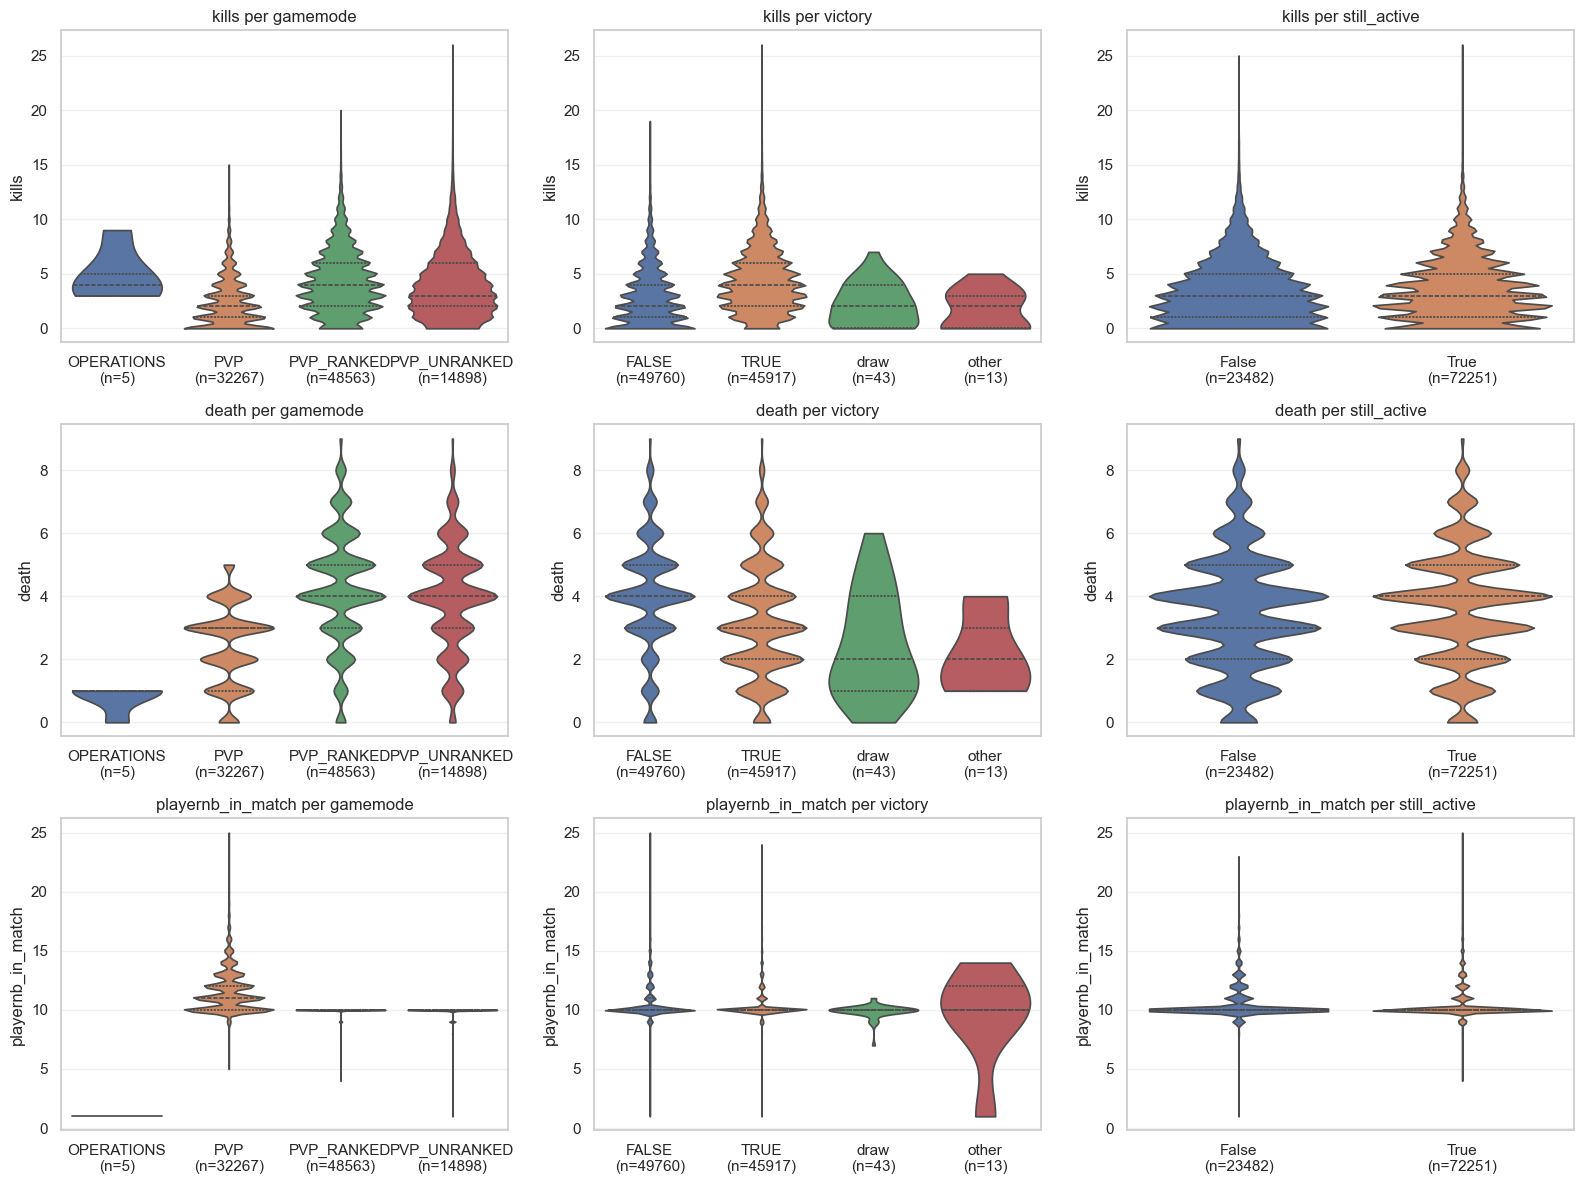

In [ ]:
HUE_COLUMNS: list[str] = ['victory', 'still_active']
GAMEMODE_ORDER: list[str] = ['PVP_RANKED', 'PVP_UNRANKED', 'PVP']

# split violins need exactly 2 levels per hue: drop draw / other / OPERATIONS (61 rows)
df_split: pd.DataFrame = (
    df_player_matches
    .filter(pl.col('victory').is_in(['TRUE', 'FALSE']), pl.col('gamemode').is_in(GAMEMODE_ORDER))
    .with_columns(pl.col('still_active').cast(pl.String).str.to_titlecase())
    .to_pandas()
)

fig, axes = plt.subplots(len(NUM_COLUMNS), len(HUE_COLUMNS), figsize=(16, 14))
for row_index, num_column in enumerate(NUM_COLUMNS):
    for col_index, hue_column in enumerate(HUE_COLUMNS):
        ax = axes[row_index][col_index]
        sns.violinplot(
            data=df_split, x='gamemode', y=num_column, hue=hue_column,
            order=GAMEMODE_ORDER, hue_order=sorted(df_split[hue_column].unique(), reverse=True),
            split=True, inner='quartile', cut=0, density_norm='width', gap=0.05, ax=ax,
        )
        ax.set_title(f'{num_column} per gamemode, split by {hue_column}')
        ax.set_xlabel('')
        ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

print(df_split.groupby(['gamemode', 'victory']).size().unstack())

In [ ]:
df_player_matches.group_by('gamemode').agg(
    pl.len().alias('rows'),
    pl.col('kills').mean().round(2).alias('kills_mean'),
    pl.col('death').mean().round(2).alias('death_mean'),
    pl.col('playernb_in_match').median().alias('lobby_median'),
    pl.col('playernb_in_match').max().alias('lobby_max'),
    (pl.col('playernb_in_match') != 10).mean().round(3).alias('share_lobby_not_10'),
).sort('rows', descending=True)

gamemode,rows,kills_mean,death_mean,lobby_median,lobby_max,share_lobby_not_10
str,u32,f64,f64,f64,i64,f64
"""PVP_RANKED""",48563,4.25,4.24,10.0,10,0.052
"""PVP""",32267,2.27,2.44,11.0,25,0.685
"""PVP_UNRANKED""",14898,3.92,3.94,10.0,10,0.067
"""OPERATIONS""",5,4.8,0.8,1.0,1,1.0


Observation:
- `PVP` lobby sizes are spread (up to 25) and its kills/deaths are about half of ranked/unranked (2.3 vs 4.2): **a different population**, not comparable to PVP_RANKED.
- `OPERATIONS` has only 5 rows with a lobby of 1 (PvE?): too small to analyse, candidate to exclude.
- `victory`: winners 4.3 kills / 3.2 deaths vs losers 2.9 / 4.0 (expected, sanity check OK); `draw`/`other` have 56 rows, too few to model.
- `still_active`: inactive players have only slightly lower means (3.4 vs 3.6 kills): raw performance alone will probably not explain churn.

## 6. Scatterplot kills / death

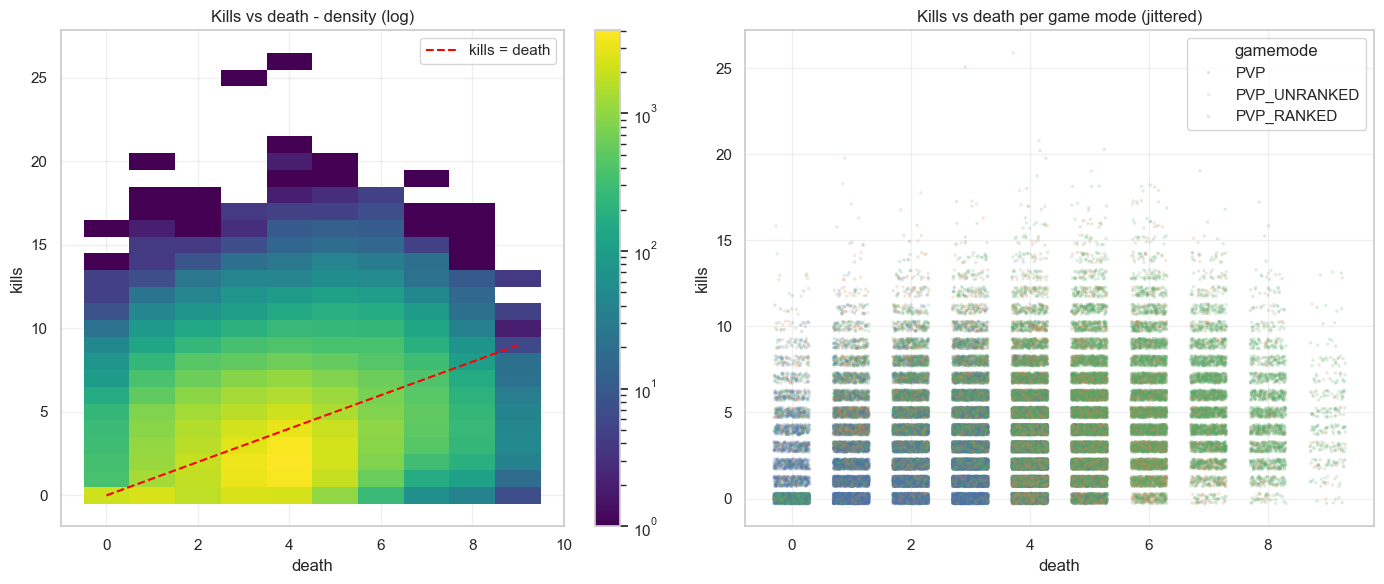

correlation kills/death: 0.24
rows with kills >= 15  : 160
rows with death == 0   : 4082


In [ ]:
df_scatter = df_player_matches.drop_nulls(['kills', 'death']).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# left: values are integers, so points overlap: 2D histogram shows the density
sns.histplot(data=df_scatter, x='death', y='kills', discrete=(True, True), cmap='viridis', cbar=True, norm=LogNorm(), vmin=None, vmax=None, ax=axes[0])
axes[0].plot([0, 9], [0, 9], color='red', linestyle='--', label='kills = death')
axes[0].set_title('Kills vs death - density (log)')
axes[0].legend()

# right: per game mode, jittered
rng = np.random.default_rng(0)
df_jitter = df_scatter[df_scatter['gamemode'] != 'OPERATIONS'].copy()
df_jitter['death_jitter'] = df_jitter['death'] + rng.uniform(-0.3, 0.3, len(df_jitter))
df_jitter['kills_jitter'] = df_jitter['kills'] + rng.uniform(-0.3, 0.3, len(df_jitter))
sns.scatterplot(data=df_jitter, x='death_jitter', y='kills_jitter', hue='gamemode', s=6, alpha=0.2, linewidth=0, ax=axes[1])
axes[1].set_title('Kills vs death per game mode (jittered)')
axes[1].set_xlabel('death')
axes[1].set_ylabel('kills')

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print('correlation kills/death:', round(df_scatter['kills'].corr(df_scatter['death']), 3))
print('rows with kills >= 15  :', (df_scatter['kills'] >= 15).sum())
print('rows with death == 0   :', (df_scatter['death'] == 0).sum())

Observation:
- Deaths hit a **hard ceiling of 9** (vertical wall on the right) while kills go up to 26.
- The cloud is dense for kills 0-8 / death 1-6; points far above the diagonal (kills >= 15) are the real outliers: plausible, but 160 rows only.
- Correlation kills/death is weak (0.24): they are not mirror images.
- The (0, 0) point is heavy: the AFK / dropped-player suspect group.
- K/D ratio will be unstable: 4,082 rows have `death == 0` (division by zero).

## Conclusion - data quality assessment

| Dimension | Verdict | Detail |
|---|---|---|
| Completeness | Good, one incident | 153 null kills/death (0.16%), 152 of them on 2025-12-09; 6 teammateid, 11 opponentid |
| Uniqueness | Good | no duplicated (player, match) |
| Validity | Medium | `victory` has `draw`/`other`, `OPERATIONS` has 5 rows, death capped at 9 |
| Consistency | Medium | lobby size 1-25 while the game looks like 10 players (but `playernb_in_match` = teammates + opponents + 1 on 100% of rows); 2,134 rows with 0 kills and 0 deaths |
| Representativeness | Watch | 840 players, median 28 matches per player, max 1974: a few heavy users dominate |

Outliers: the kills tail and the lobby size are the visible ones. Kills are probably real, lobby size reveals a **different match type**.

## What to do next

1. **Decide the perimeter**: keep `PVP_RANKED` + `PVP_UNRANKED` (lobby = 10) for performance analysis, treat `PVP` separately, drop or flag `OPERATIONS` and `draw`/`other`.
2. **Handle nulls**: the 152 rows of 2025-12-09 come from an incident; ask the data team whether the day can be re-extracted, otherwise exclude those rows from performance metrics (they are still valid for activity / churn features).
3. **Flag, do not delete**, AFK-like rows (0 kills and 0 deaths) and extreme kills; test the impact on the metrics.
4. **Validate with the business**: meaning of `PVP` vs ranked, the death cap at 9, lobby above 10, and how `still_active` is defined (cut-off date).
5. **Player-level view**: aggregate per player (matches, K/D, win rate, days since last match). The target `still_active` is per player but repeated on every row, so row-level modelling over-weights heavy players.
6. **Check time consistency**: is `still_active` coherent with each player's last `match_datetime`?
7. Then feature engineering and a churn baseline.